In [202]:
import pandas as pd
import torch
from torch import nn

from pathlib import Path
import os
import random

In [203]:
# Le chemin des données
data_path = Path('data/pizza_steak_sushi')
data_path

WindowsPath('data/pizza_steak_sushi')

In [204]:
# train and test directory
train_dir = data_path / "train"
test_dir = data_path / "test"

train_dir, test_dir

(WindowsPath('data/pizza_steak_sushi/train'),
 WindowsPath('data/pizza_steak_sushi/test'))

In [205]:
# Une fonction pour parcourir le dossier

def walkthrough(dir_path : Path) :
    for dirpath, dirnames, filenames in os.walk(dir_path):
        print(f"There are {len(dirnames)} directories, In this folder : {dirpath}, there are : {len(filenames)} images")   
        

walkthrough(data_path)

There are 2 directories, In this folder : data\pizza_steak_sushi, there are : 0 images
There are 3 directories, In this folder : data\pizza_steak_sushi\test, there are : 0 images
There are 0 directories, In this folder : data\pizza_steak_sushi\test\pizza, there are : 25 images
There are 0 directories, In this folder : data\pizza_steak_sushi\test\steak, there are : 19 images
There are 0 directories, In this folder : data\pizza_steak_sushi\test\sushi, there are : 31 images
There are 3 directories, In this folder : data\pizza_steak_sushi\train, there are : 0 images
There are 0 directories, In this folder : data\pizza_steak_sushi\train\pizza, there are : 78 images
There are 0 directories, In this folder : data\pizza_steak_sushi\train\steak, there are : 75 images
There are 0 directories, In this folder : data\pizza_steak_sushi\train\sushi, there are : 72 images


In [206]:
image_path = list(train_dir.glob('*/*.jpg'))
img = random.choice(image_path)

class_img = img.parent.stem

class_img



'pizza'

La classe de l'image est : sushi
La taille de l'image est :  (512, 384)
L' extension de l'image : JPEG


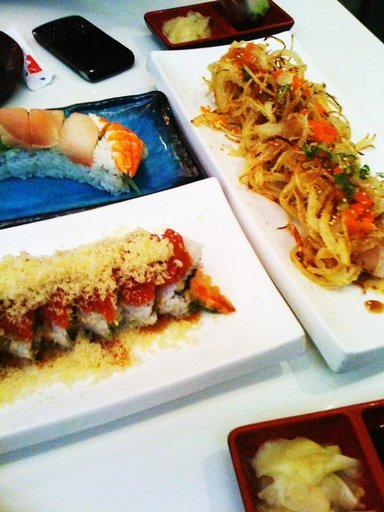

In [207]:
# Plot a random image
import random
from PIL import Image

random.seed(42)


# paths de toutttes les images dans train
images_path =  list(train_dir.glob('*/*.jpg'))  # all the images in data/pizza_steak_sushi/train


# On choisit une seule image 
image_path = random.choice(images_path)


# La classe de cette image est 
image_class = image_path.parent.stem


# plotter l'image avec se classe
img = Image.open(image_path)



print(f"La classe de l'image est : {image_class}")
print(f"La taille de l'image est :  {img.height, img.width}")
print(f"L' extension de l'image : {img.format}")
img



In [208]:
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from typing import List, Dict, Tuple

In [209]:
# Now let's transform those images 
# PHASE 1: COMPOSE

train_data_transform = transforms.Compose([
                                transforms.Resize(size=(64, 64)),
                                transforms.Grayscale(),
                                transforms.TrivialAugmentWide(),
                                transforms.ToTensor()
])


test_data_transforms = transforms.Compose([
                                transforms.Resize(size=(64, 64)),
                                transforms.Grayscale(),
                                # NO DATA AUGMENTATION FOR TEST DATA
                                transforms.ToTensor()
])



In [210]:
# Then we need to use a custom dataset function, to link between images and corresponding labels
# Before that we need a function that returns classe names as list and classnames with id as dict

def find_classes(directory: str) -> Tuple[List[str], Dict[str, int]]:
    
    # get class names
    classes = sorted(entry.name for entry in os.scandir(directory) if entry.is_dir())

    if not classes:
        raise FileNotFoundError(f"No classes found in this directory {directory}!")
    

    # convert classes to dictionnary
    class_to_idx = {cls_name: index for index, cls_name in enumerate(classes)}    
    
    return classes, class_to_idx

find_classes(train_dir)


    



(['pizza', 'steak', 'sushi'], {'pizza': 0, 'steak': 1, 'sushi': 2})

In [211]:
# Now to our custom dataset

class CustomDataset(Dataset):
    def __init__(self, targ_dir: str, transform= None) -> None:
        self.paths = list(Path(targ_dir).glob('*/*.jpg'))
        self.transform = transform
        self.classes, self.class_to_idx = find_classes(targ_dir)
        
        
    def load_image(self, index: int) -> Image.Image:
        image_path = self.paths[index]
        return Image.open(image_path)
    
    
    def __len__(self) -> int:
        return len(self.paths)

    def __getitem__(self, index: int) -> Tuple[torch.Tensor, int]:
        img = self.load_image(index)
        class_name = self.paths[index].parent.name
        class_idx = self.class_to_idx[class_name]
        
        if self.transform:
            return self.transform(img), class_idx 
        else:
            return img, class_idx            

In [212]:
# appliquer notre fonction

train_data_custom = CustomDataset(train_dir, train_data_transform)

test_data_custom = CustomDataset(test_dir, test_data_transforms)


In [213]:
len(train_data_custom), len(test_data_custom)

(225, 75)

In [214]:
class_names = train_data_custom.classes
class_names

['pizza', 'steak', 'sushi']

In [215]:
test_data_custom.class_to_idx

{'pizza': 0, 'steak': 1, 'sushi': 2}

In [216]:
# Load images with DataLoader
train_data_loader = DataLoader(train_data_custom, 
                                batch_size= 32,     
                                shuffle= True)

test_data_loader = DataLoader(test_data_custom,
                                batch_size= 32,
                                shuffle= False)



In [217]:
# Le modèle
class Food101Model(nn.Module):
    def __init__(self, input_shape: int, hidden_units: int, output_shape: int):
        super().__init__()
        
        self.block1 = nn.Sequential(
            nn.Conv2d(in_channels= input_shape, out_channels= hidden_units, kernel_size= 3, stride= 1, padding= 1),
            nn.ReLU(),
            nn.Conv2d(in_channels= hidden_units, out_channels= hidden_units, kernel_size= 3, stride= 1, padding= 1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size= 2, stride= 2)
        )
        
        
        self.block2 = nn.Sequential(
            nn.Conv2d(in_channels= hidden_units, out_channels= hidden_units, kernel_size= 3, stride= 1, padding= 1),
            nn.ReLU(),
            nn.Conv2d(in_channels= hidden_units, out_channels= hidden_units, kernel_size= 3, stride= 1, padding= 1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size= 2, stride= 2)
        )
        
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features= hidden_units*16*16, out_features= output_shape))
        
    def forward(self, x:torch.Tensor):
        return self.classifier(self.block2(self.block1(x)))

In [218]:
# iniitalisation du modéle

model = Food101Model(input_shape= 1, hidden_units= 10, output_shape= len(class_names))
model.state_dict

<bound method Module.state_dict of Food101Model(
  (block1): Sequential(
    (0): Conv2d(1, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2560, out_features=3, bias=True)
  )
)>

In [219]:
from torchinfo import summary
# On remplace xomme suit  (Batch, C, H, W) 
summary(model, input_size=(32, 1, 64, 64)) 


Layer (type:depth-idx)                   Output Shape              Param #
Food101Model                             [32, 3]                   --
├─Sequential: 1-1                        [32, 10, 32, 32]          --
│    └─Conv2d: 2-1                       [32, 10, 64, 64]          100
│    └─ReLU: 2-2                         [32, 10, 64, 64]          --
│    └─Conv2d: 2-3                       [32, 10, 64, 64]          910
│    └─ReLU: 2-4                         [32, 10, 64, 64]          --
│    └─MaxPool2d: 2-5                    [32, 10, 32, 32]          --
├─Sequential: 1-2                        [32, 10, 16, 16]          --
│    └─Conv2d: 2-6                       [32, 10, 32, 32]          910
│    └─ReLU: 2-7                         [32, 10, 32, 32]          --
│    └─Conv2d: 2-8                       [32, 10, 32, 32]          910
│    └─ReLU: 2-9                         [32, 10, 32, 32]          --
│    └─MaxPool2d: 2-10                   [32, 10, 16, 16]          --
├─Sequentia

In [220]:
# loss function et optimizer

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params= model.parameters(), lr= 0.01)

In [221]:
from torchmetrics import Accuracy

accuracy_fn = Accuracy('multiclass', num_classes= len(class_names))

In [222]:
# TRAIN LOOP

def train_step(model: torch.nn.Module,
                data_loader: torch.utils.data.DataLoader,
                loss_fn: torch.nn.Module,
                optimizer: torch.optim.Optimizer,
                accuracy_fn):
    
    train_loss, train_acc = 0,0
    model.train()
    
    for batch, (X,y) in enumerate(data_loader):
        y_pred = model(X)
        loss = loss_fn(y_pred, y)
        train_loss+= loss
        train_acc += accuracy_fn(y_pred, y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
    train_loss/= len(data_loader)
    train_acc /= len(data_loader)
    
    print(f"Train accuracy : {train_acc:.2f} | Train loss : {train_loss:.5f}")    

In [223]:
# TEST LOOP

def test_step(model: torch.nn.Module,
                data_loader : torch.utils.data.Dataset,
                loss_fn: torch.nn.Module,
                accuracy_fn  ):
    
    test_loss, test_acc = 0,0
    model.eval()
    with torch.inference_mode():
        for X, y in data_loader:
            test_pred = model(X)
            test_loss+= loss_fn(test_pred, y)
            test_acc += accuracy_fn(test_pred, y)
        test_loss /=len(data_loader)
        test_acc /= len(data_loader)
        print(f"Test accuracy : {test_acc:.2f} | Test loss : {test_loss:.5f}")  

In [224]:
# Tester

torch.manual_seed(42)

epochs = 20

for epoch in range(epochs):
    print(f"Epoch : {epoch}\n")
    train_step(model, train_data_loader, loss_fn, optimizer, accuracy_fn)
    test_step(model, test_data_loader, loss_fn, accuracy_fn)

Epoch : 0

Train accuracy : 0.28 | Train loss : 1.10213
Test accuracy : 0.54 | Test loss : 1.09471
Epoch : 1

Train accuracy : 0.41 | Train loss : 1.09766
Test accuracy : 0.26 | Test loss : 1.09851
Epoch : 2

Train accuracy : 0.30 | Train loss : 1.10199
Test accuracy : 0.26 | Test loss : 1.10424
Epoch : 3

Train accuracy : 0.43 | Train loss : 1.09234
Test accuracy : 0.26 | Test loss : 1.10011
Epoch : 4

Train accuracy : 0.30 | Train loss : 1.10124
Test accuracy : 0.26 | Test loss : 1.10010
Epoch : 5

Train accuracy : 0.43 | Train loss : 1.09221
Test accuracy : 0.26 | Test loss : 1.09451
Epoch : 6

Train accuracy : 0.43 | Train loss : 1.08988
Test accuracy : 0.26 | Test loss : 1.09743
Epoch : 7

Train accuracy : 0.43 | Train loss : 1.08772
Test accuracy : 0.26 | Test loss : 1.10111
Epoch : 8

Train accuracy : 0.30 | Train loss : 1.11260
Test accuracy : 0.26 | Test loss : 1.10665
Epoch : 9

Train accuracy : 0.43 | Train loss : 1.08593
Test accuracy : 0.26 | Test loss : 1.11324
Epoch : 10